In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
# ================= CONFIGURAZIONE =================

class1_paths = [
    #"Autoinduced_Traces/filter_reports/filtered/bodyguard_adc1.csv"
    "Autoinduced_Traces/bodyguard_adc1.csv"
]

class2_paths = [
    #"Induced_Traces/filter_reports/filtered/bodyguard_adc1.csv"
    "Induced_Traces/bodyguard_adc1.csv"
]

class1_name = "Self-Induced"
class2_name = "Attack-Induced"

class1_color = "royalblue"
class2_color = "crimson"

fs = 5e6
dt = 1e6 / fs  # Periodo di campionamento [µs]
k_std = 2

alpha_traces = 0.03
alpha_std = 0.20
linewidth_traces = 0.5
linewidth_mean = 2

# Limiti asse X [µs]
x_min = 800
x_max = 900

# Limiti asse Y
y_min = 160
y_max = 260

# Visualizzazione
show_traces = True
show_mean = True
show_std = True
show_recovery = True

# Adattamento automatico asse Y
auto_zoom_y = False

y_label = "ADC counts"

# ==================================================

Autoinduced_Traces/bodyguard_adc1.csv: 100 tracce caricate

Self-Induced: 100 traces
Induced_Traces/bodyguard_adc1.csv: 100 tracce caricate

Attack-Induced: 100 traces


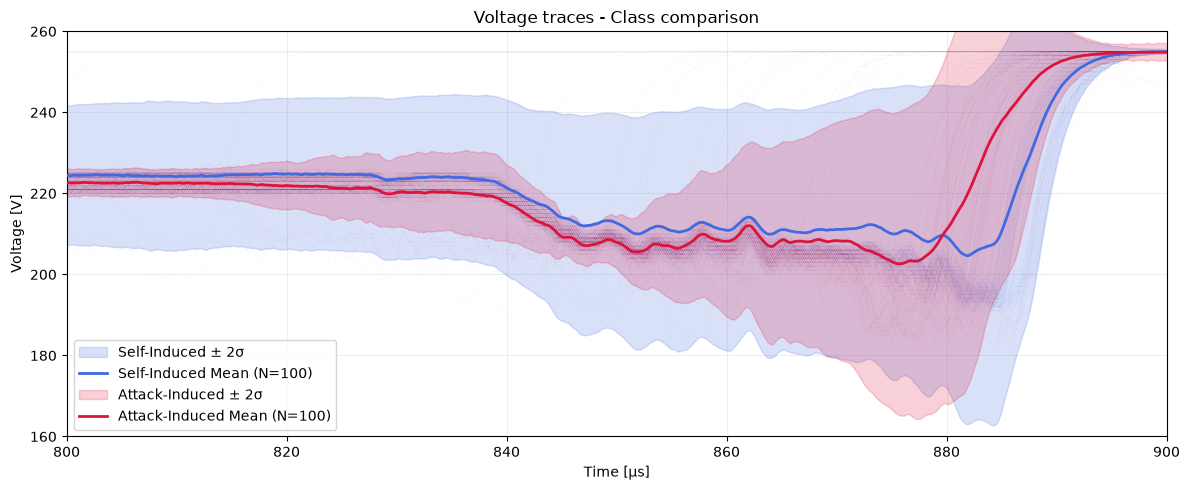

In [18]:

def load_traces(file_paths):

    all_traces = []
    all_ids = []
    expected_samples = None

    for file_path in file_paths:

        df = pd.read_csv(file_path, header=None)

        ids = df.iloc[:, 0].to_numpy()
        data = df.iloc[:, 1:].to_numpy(dtype=float)

        if expected_samples is None:
            expected_samples = data.shape[1]

        elif data.shape[1] != expected_samples:
            raise ValueError(
                f"{file_path}: trovati {data.shape[1]} campioni, "
                f"attesi {expected_samples}"
            )

        all_traces.append(data)
        all_ids.append(ids)

        print(f"{file_path}: {data.shape[0]} tracce caricate")

    return (
        np.concatenate(all_traces, axis=0),
        np.concatenate(all_ids)
    )


# ================= DEFINIZIONE CLASSI ==============

classes_config = [
    {
        "paths": class1_paths,
        "name": class1_name,
        "color": class1_color
    },
    {
        "paths": class2_paths,
        "name": class2_name,
        "color": class2_color
    }
]

classes = []
expected_samples = None

# ================= CARICAMENTO ====================

for config in classes_config:

    # Ignora le classi senza CSV
    if not config["paths"]:
        continue

    traces, ids = load_traces(config["paths"])

    n_traces, n_samples = traces.shape

    if n_traces < 2:
        raise ValueError(
            f"{config['name']}: servono almeno due tracce"
        )

    if expected_samples is None:
        expected_samples = n_samples

    elif n_samples != expected_samples:
        raise ValueError(
            "Numero di campioni differente tra le classi"
        )

    classes.append({
        "name": config["name"],
        "color": config["color"],
        "traces": traces,
        "ids": ids,
        "mean": np.mean(traces, axis=0),
        "std": np.std(traces, axis=0, ddof=1),
        "n_traces": n_traces
    })

    print(f"\n{config['name']}: {n_traces} traces")


if not classes:
    raise ValueError("Nessuna classe contiene CSV")


# Asse temporale [µs]
t = np.arange(expected_samples) / fs * 1e6


# ================= PLOT ===========================

fig, ax = plt.subplots(figsize=(12, 5))

for cls in classes:

    traces = cls["traces"]
    mean = cls["mean"]
    std = cls["std"]
    name = cls["name"]
    color = cls["color"]

    # Singole tracce
    if show_traces:
        for trace in traces:
            ax.plot(
                t, trace,
                color=color,
                alpha=alpha_traces,
                linewidth=linewidth_traces,
                zorder=1
            )

    # Banda di deviazione standard
    if show_std:
        ax.fill_between(
            t,
            mean - k_std * std,
            mean + k_std * std,
            color=color,
            alpha=alpha_std,
            label=f"{name} ± {k_std}σ",
            zorder=2
        )

    # Curva media
    if show_mean:
        ax.plot(
            t, mean,
            color=color,
            linewidth=linewidth_mean,
            label=f"{name} Mean (N={len(traces)})",
            zorder=3
        )


# ================= ZOOM ===========================

ax.set_xlim(left=x_min, right=x_max)

if auto_zoom_y:

    mask = np.ones(t.shape, dtype=bool)

    if x_min is not None:
        mask &= t >= x_min

    if x_max is not None:
        mask &= t <= x_max

    if np.any(mask):

        visible_data = []

        for cls in classes:

            mean = cls["mean"]
            std = cls["std"]
            traces = cls["traces"]

            if show_traces:
                visible_data.append(traces[:, mask])

            if show_mean:
                visible_data.append(mean[mask])

            if show_std:
                visible_data.extend([
                    mean[mask] - k_std * std[mask],
                    mean[mask] + k_std * std[mask]
                ])

        if visible_data:

            lower = min(np.min(v) for v in visible_data)
            upper = max(np.max(v) for v in visible_data)

            margin = 0.05 * (upper - lower)

            y_min = lower - margin
            y_max = upper + margin

ax.set_ylim(bottom=y_min, top=y_max)


# ================= FORMATTAZIONE =================

ax.set_xlabel("Time [µs]")
ax.set_ylabel("Voltage [V]")

if len(classes) == 1:
    ax.set_title(f"Voltage traces - {classes[0]['name']}")
else:
    ax.set_title("Voltage traces - Class comparison")

if show_mean or show_std:
    ax.legend(loc="best")

ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

Autoinduced_Traces/bodyguard_adc1.csv: 150 tracce caricate
Induced_Traces/bodyguard_adc1.csv: 100 tracce caricate

Self-Induced
Total traces: 150
Valid traces: 129
Rejected traces: 21
Mean t_recovery: 889.627 µs
Std t_recovery: 8.164 µs

Attack-Induced
Total traces: 100
Valid traces: 100
Rejected traces: 0
Mean t_recovery: 884.886 µs
Std t_recovery: 5.912 µs


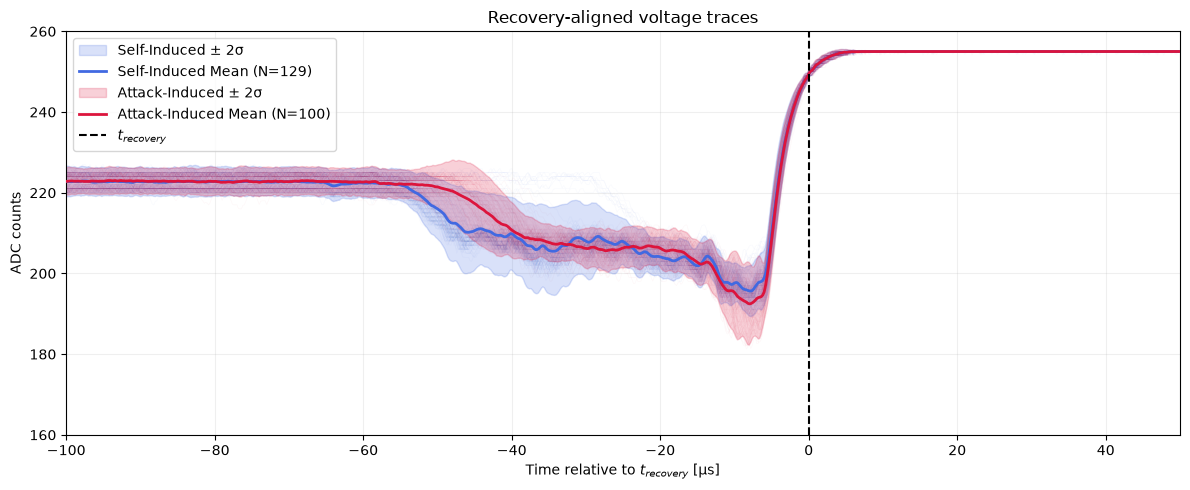

In [23]:
# ================= NUOVI LIMITI ===================

# Limiti asse X [µs]
x_min = -100
x_max = 50

# Limiti asse Y
y_min = 160
y_max = 260

# ================= ALLINEAMENTO ===================

align_recovery = True

# Percentuale dell'escursione
recovery_fraction = 0.90

# Finestra per stimare il livello inferiore [µs]
low_window = (845, 875)

# Finestra per stimare il livello superiore [µs]
high_window = (895, 900)

# Finestra di ricerca del recovery [µs]
recovery_window = (850, 900)

# Smoothing per il solo rilevamento del recovery
# 1 = nessuno smoothing
smooth_samples = 3

# Campioni consecutivi sopra soglia
hold_samples = 5

# Escursione minima accettabile
min_excursion = 10

# ==================================================


def load_traces(file_paths):

    all_traces = []
    all_ids = []
    expected_samples = None

    for file_path in file_paths:

        df = pd.read_csv(file_path, header=None)

        ids = df.iloc[:, 0].to_numpy()
        data = df.iloc[:, 1:].to_numpy(dtype=float)

        if expected_samples is None:
            expected_samples = data.shape[1]

        elif data.shape[1] != expected_samples:
            raise ValueError(
                f"{file_path}: numero di campioni differente"
            )

        all_traces.append(data)
        all_ids.append(ids)

        print(f"{file_path}: {len(data)} tracce caricate")

    return (
        np.concatenate(all_traces, axis=0),
        np.concatenate(all_ids)
    )


# ============== DETECTION T_RECOVERY ==============

def detect_recovery(trace, t):

    if not np.all(np.isfinite(trace)):
        return np.nan

    # Smoothing per la detection, non per il plot
    if smooth_samples > 1:

        filtered = (
            pd.Series(trace)
            .rolling(
                window=smooth_samples,
                center=True,
                min_periods=1
            )
            .median()
            .to_numpy()
        )

    else:
        filtered = trace.copy()

    # Maschere temporali
    low_mask = (
        (t >= low_window[0]) &
        (t <= low_window[1])
    )

    high_mask = (
        (t >= high_window[0]) &
        (t <= high_window[1])
    )

    search_mask = (
        (t >= recovery_window[0]) &
        (t <= recovery_window[1])
    )

    if not np.any(low_mask) or not np.any(high_mask):
        return np.nan

    # Stima robusta dei livelli della rampa
    v_low = np.percentile(filtered[low_mask], 10)
    v_high = np.median(filtered[high_mask])

    excursion = v_high - v_low

    if excursion < min_excursion:
        return np.nan

    # Soglia relativa
    v_threshold = v_low + recovery_fraction * excursion

    # Ricerca degli attraversamenti crescenti
    crossings = np.where(
        (filtered[:-1] < v_threshold) &
        (filtered[1:] >= v_threshold)
    )[0] + 1

    # Selezione dell'attraversamento valido
    for idx in crossings:

        if not search_mask[idx]:
            continue

        if idx + hold_samples > len(filtered):
            continue

        # Verifica permanenza sopra soglia
        if not np.all(
            filtered[idx:idx + hold_samples] >= v_threshold
        ):
            continue

        # Interpolazione lineare sub-campione
        v0 = filtered[idx - 1]
        v1 = filtered[idx]

        t0 = t[idx - 1]
        t1 = t[idx]

        fraction = (v_threshold - v0) / (v1 - v0)

        t_recovery = t0 + fraction * (t1 - t0)

        return t_recovery

    return np.nan


# ================= DEFINIZIONE CLASSI ==============

classes_config = [
    {
        "paths": class1_paths,
        "name": class1_name,
        "color": class1_color
    },
    {
        "paths": class2_paths,
        "name": class2_name,
        "color": class2_color
    }
]

classes = []
expected_samples = None


# ================= CARICAMENTO ====================

for config in classes_config:

    if not config["paths"]:
        continue

    traces, ids = load_traces(config["paths"])

    n_traces, n_samples = traces.shape

    if expected_samples is None:
        expected_samples = n_samples

    elif n_samples != expected_samples:
        raise ValueError(
            "Numero di campioni differente tra le classi"
        )

    classes.append({
        "name": config["name"],
        "color": config["color"],
        "traces": traces,
        "ids": ids
    })

if not classes:
    raise ValueError("Nessuna classe contiene CSV")

# Asse temporale originale
t_original = np.arange(expected_samples) * dt


# ================= DETECTION ======================

if align_recovery:

    for cls in classes:

        traces = cls["traces"]

        recovery_times = np.array([
            detect_recovery(trace, t_original)
            for trace in traces
        ])

        valid = np.isfinite(recovery_times)

        print(f"\n{cls['name']}")
        print(f"Total traces: {len(traces)}")
        print(f"Valid traces: {np.sum(valid)}")
        print(f"Rejected traces: {np.sum(~valid)}")

        if np.sum(valid) < 2:
            raise ValueError(
                f"{cls['name']}: recovery validi insufficienti"
            )

        # Conservazione degli identificativi scartati
        cls["rejected_ids"] = cls["ids"][~valid]

        # Conservazione delle sole tracce valide
        cls["traces"] = traces[valid]
        cls["ids"] = cls["ids"][valid]
        cls["recovery_times"] = recovery_times[valid]

        print(
            f"Mean t_recovery: "
            f"{np.mean(cls['recovery_times']):.3f} µs"
        )

        print(
            f"Std t_recovery: "
            f"{np.std(cls['recovery_times'], ddof=1):.3f} µs"
        )


# ================= ALLINEAMENTO ===================

if align_recovery:

    # Intervallo temporale comune a tutte le tracce
    all_recovery_times = np.concatenate([
        cls["recovery_times"] for cls in classes
    ])

    t_start = -np.min(all_recovery_times)

    t_end = (
        t_original[-1] - np.max(all_recovery_times)
    )

    # Asse temporale comune contenente esattamente t=0
    start_idx = int(np.ceil(t_start / dt))
    end_idx = int(np.floor(t_end / dt))

    if start_idx > end_idx:
        raise ValueError("Nessun intervallo temporale comune")

    t = np.arange(start_idx, end_idx + 1) * dt

    for cls in classes:

        aligned_traces = []

        for trace, t_recovery in zip(
            cls["traces"],
            cls["recovery_times"]
        ):

            # Traslazione e interpolazione
            aligned = np.interp(
                t + t_recovery,
                t_original,
                trace
            )

            aligned_traces.append(aligned)

        cls["original_traces"] = cls["traces"]

        cls["traces"] = np.array(aligned_traces)

else:

    t = t_original.copy()


# ================= STATISTICHE ====================

for cls in classes:

    traces = cls["traces"]

    if len(traces) < 2:
        raise ValueError(
            f"{cls['name']}: servono almeno due tracce"
        )

    cls["mean"] = np.mean(traces, axis=0)
    cls["std"] = np.std(traces, axis=0, ddof=1)
    cls["n_traces"] = len(traces)


# ================= PLOT ===========================

fig, ax = plt.subplots(figsize=(12, 5))

for cls in classes:

    traces = cls["traces"]
    mean = cls["mean"]
    std = cls["std"]
    name = cls["name"]
    color = cls["color"]

    # Singole tracce
    if show_traces:

        for trace in traces:

            ax.plot(
                t,
                trace,
                color=color,
                alpha=alpha_traces,
                linewidth=linewidth_traces,
                zorder=1
            )

    # Banda di deviazione standard
    if show_std:

        ax.fill_between(
            t,
            mean - k_std * std,
            mean + k_std * std,
            color=color,
            alpha=alpha_std,
            label=f"{name} ± {k_std}σ",
            zorder=2
        )

    # Media
    if show_mean:

        ax.plot(
            t,
            mean,
            color=color,
            linewidth=linewidth_mean,
            label=f"{name} Mean (N={len(traces)})",
            zorder=3
        )


# Indicatore del punto di recovery
if align_recovery and show_recovery:

    ax.axvline(
        x=0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=r"$t_{recovery}$",
        zorder=4
    )


# ================= ZOOM ===========================

ax.set_xlim(left=x_min, right=x_max)

if auto_zoom_y:

    mask = np.ones(t.shape, dtype=bool)

    if x_min is not None:
        mask &= t >= x_min

    if x_max is not None:
        mask &= t <= x_max

    if np.any(mask):

        visible_data = []

        for cls in classes:

            mean = cls["mean"]
            std = cls["std"]

            if show_traces:
                visible_data.append(cls["traces"][:, mask])

            if show_mean:
                visible_data.append(mean[mask])

            if show_std:
                visible_data.extend([
                    mean[mask] - k_std * std[mask],
                    mean[mask] + k_std * std[mask]
                ])

        if visible_data:

            lower = min(np.min(v) for v in visible_data)
            upper = max(np.max(v) for v in visible_data)

            margin = 0.05 * (upper - lower)

            y_min = lower - margin
            y_max = upper + margin

ax.set_ylim(bottom=y_min, top=y_max)


# ================= FORMATTAZIONE ==================

if align_recovery:

    ax.set_xlabel(r"Time relative to $t_{recovery}$ [µs]")
    ax.set_title("Recovery-aligned voltage traces")

else:

    ax.set_xlabel("Time [µs]")
    ax.set_title("Voltage traces")

ax.set_ylabel(y_label)

ax.legend(loc="best")
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()